<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/DGM_for_PDEs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DGM for 1D Heat Equation

## First version

Recall the 1D heat equation:
$$
  u_t(t,x) = 0.5\sigma^2 u_{xx}(t,x), \qquad \hbox{ for all } (t,x) \in [0,T] \times [0,L].
$$
We consider an initial condition:
$$
  u(0,x) = \sin(\pi x / L), \qquad x \in [0,L],
$$
and boundary conditions:
$$
  u(t,0) = u(t,L) = 0, \qquad t \in [0,T].
$$

We solve it using the DGM, with a basic FNN architecture.

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Define the neural network
class DGMNet(nn.Module):
    def __init__(self, hidden_size):
        super(DGMNet, self).__init__()  # Correct super call
        self.fc1 = nn.Linear(2, hidden_size)  # Input: (t, x)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.fc4 = nn.Linear(hidden_size, 1)  # Output: u(t, x)
        self.activation = nn.Sigmoid()

    def forward(self, tx):
        out = self.activation(self.fc1(tx))
        out = self.activation(self.fc2(out))
        out = self.activation(self.fc3(out))
        out = self.fc4(out)  # No activation on the output layer
        return out

# Define the PDE residual
def pde_residual(model, t, x, sigma):
    # Ensure that t and x require gradients
    t.requires_grad_()
    x.requires_grad_()

    # Pass input through the model to get u(t, x)
    tx = torch.cat([t, x], dim=1)
    u = model(tx)  # u(t, x)

    # Compute gradients with autograd
    u_t = torch.autograd.grad(u,t,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u,x,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x,x,grad_outputs=torch.ones_like(u), create_graph=True)[0]

    # PDE residual: u_t - 0.5 * sigma^2 * u_xx = 0
    residual = u_t - 0.5*sigma**2*u_xx
    return residual

# Initial condition: u(0, x) = sin(pi * x / L)
def initial_condition_loss(model, x, L):
    t = torch.zeros_like(x)  # t=0
    u_pred = model(torch.cat([t,x], dim=1))
    u_true = torch.sin(np.pi*x/L)
    return torch.mean((u_pred - u_true)**2)

# Boundary conditions: u(t, 0) = u(t, L) = 0
def boundary_condition_loss(model, t, L):
    x0 = torch.zeros_like(t)  # x=0
    xL = L * torch.ones_like(t)  # x=L
    u0_pred = model(torch.cat([t,x0], dim=1))
    uL_pred = model(torch.cat([t,xL], dim=1))
    return torch.mean(u0_pred**2 + uL_pred**2)

# Training function
def train_dgm(hidden_size, num_epochs, batch_size, learning_rate, sigma, L, T, eval_every=100):
    model = DGMNet(hidden_size)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    total_losses = []
    pde_losses = []
    ic_losses = []
    bc_losses = []

    for epoch in range(1,num_epochs):
        # Sample random points in the domain
        x_batch = L * torch.rand(batch_size, 1)  # x in [0, L]
        t_batch = T * torch.rand(batch_size, 1)  # t in [0, T]

        # Compute losses
        loss_pde = (pde_residual(model, t_batch, x_batch, sigma)**2).mean()
        loss_ic = initial_condition_loss(model, x_batch, L)
        loss_bc = boundary_condition_loss(model, t_batch, L)
        loss = loss_pde + loss_ic + loss_bc

        # Backpropagation and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record losses
        total_losses.append(loss.item())
        pde_losses.append(loss_pde.item())
        ic_losses.append(loss_ic.item())
        bc_losses.append(loss_bc.item())

        # Print progress with each loss component
        if epoch % eval_every == 0:
            print(f"Epoch {epoch}, Total Loss: {loss.item():.2e}, PDE Loss: {loss_pde.item():.2e}, IC Loss: {loss_ic.item():.2e}, BC Loss: {loss_bc.item():.2e}")

    return model, total_losses, pde_losses, ic_losses, bc_losses

# Plot the losses
def plot_losses(total_losses, pde_losses, ic_losses, bc_losses):
    iterations = range(len(total_losses))

    plt.figure(figsize=(10, 6))

    # Plot the total loss and each component
    plt.semilogy(iterations, total_losses, label="Total Loss", linestyle='-', color='b')
    plt.semilogy(iterations, pde_losses, label="PDE Loss", linestyle='--', color='g')
    plt.semilogy(iterations, ic_losses, label="Initial Condition Loss", linestyle='-.', color='r')
    plt.semilogy(iterations, bc_losses, label="Boundary Condition Loss", linestyle=':', color='m')

    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.title("Loss vs Iterations")
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot the solution u(t,x)
def plot_solution(model, L, T):
    t_vals = torch.linspace(0, T, 100)
    x_vals = torch.linspace(0, L, 100)
    t_grid, x_grid = torch.meshgrid(t_vals, x_vals)
    t_flat = t_grid.flatten().unsqueeze(1)
    x_flat = x_grid.flatten().unsqueeze(1)

    u_pred = model(torch.cat([t_flat, x_flat], dim=1))
    u_pred = u_pred.reshape(t_grid.shape).detach().numpy()

    # Plot 3D surface of the solution
    fig = plt.figure(figsize=(10, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(t_grid.numpy(), x_grid.numpy(), u_pred, cmap='viridis')
    ax.set_xlabel('t')
    ax.set_ylabel('x')
    ax.set_zlabel('u(t,x)')
    plt.title('Solution of Heat Equation u(t,x)')
    plt.show()


First test: At initialization (0 epoch of training)

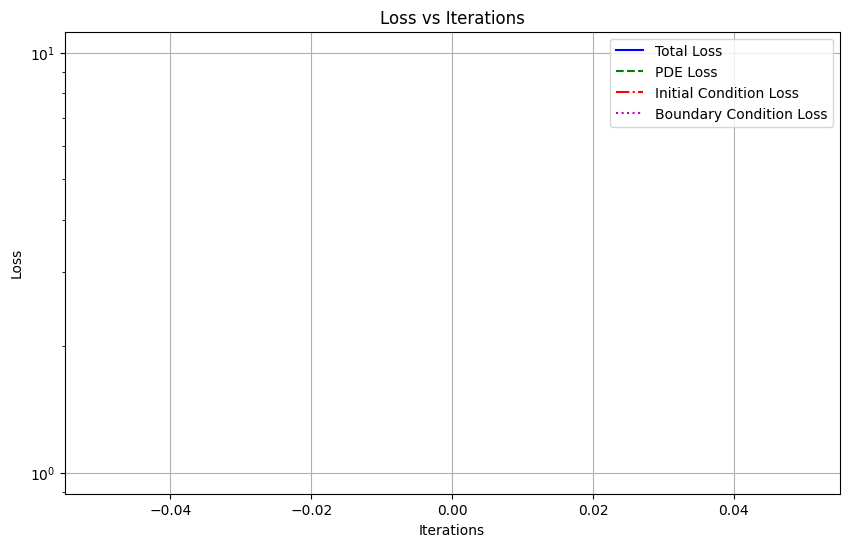

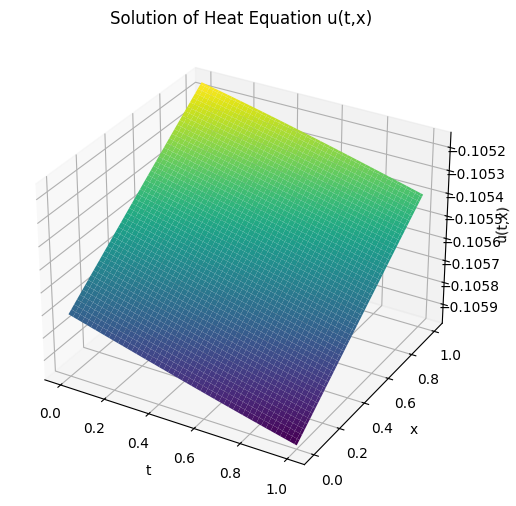

In [11]:
# Set hyperparameters
sigma = 1.0
L = 1.0
T = 1.0
hidden_size = 200
num_epochs = 0
batch_size = 100
learning_rate = 1e-3
eval_every = 100

# Train the model
model, total_losses, pde_losses, ic_losses, bc_losses = train_dgm(hidden_size, num_epochs, batch_size, learning_rate, sigma, L, T, eval_every)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses)

# Plot the solution
plot_solution(model, L, T)

We note that the NN is almost constant wrt $(t,x)$ and so the PDE residual is almost $0$. However, this is not a solution to the PDE! Indeed, if the initial and boundary conditions are not met, then it is not useful that the residual is close to $0$.

With training

Epoch 100, Total Loss: 3.34e-01, PDE Loss: 2.76e-02, IC Loss: 2.66e-01, BC Loss: 4.04e-02
Epoch 200, Total Loss: 3.39e-01, PDE Loss: 2.58e-02, IC Loss: 2.55e-01, BC Loss: 5.82e-02
Epoch 300, Total Loss: 3.45e-01, PDE Loss: 2.78e-02, IC Loss: 2.11e-01, BC Loss: 1.07e-01
Epoch 400, Total Loss: 2.54e-01, PDE Loss: 1.41e-02, IC Loss: 2.11e-01, BC Loss: 2.86e-02
Epoch 500, Total Loss: 1.40e-01, PDE Loss: 5.32e-03, IC Loss: 7.17e-02, BC Loss: 6.26e-02
Epoch 600, Total Loss: 1.36e-01, PDE Loss: 4.46e-03, IC Loss: 7.23e-02, BC Loss: 5.92e-02
Epoch 700, Total Loss: 1.16e-01, PDE Loss: 5.94e-03, IC Loss: 5.78e-02, BC Loss: 5.19e-02
Epoch 800, Total Loss: 8.77e-02, PDE Loss: 3.62e-03, IC Loss: 5.13e-02, BC Loss: 3.28e-02
Epoch 900, Total Loss: 6.95e-02, PDE Loss: 4.58e-03, IC Loss: 3.78e-02, BC Loss: 2.70e-02
Epoch 1000, Total Loss: 5.98e-02, PDE Loss: 7.04e-03, IC Loss: 2.90e-02, BC Loss: 2.38e-02
Epoch 1100, Total Loss: 4.62e-02, PDE Loss: 7.30e-03, IC Loss: 2.37e-02, BC Loss: 1.53e-02
Epoch 12

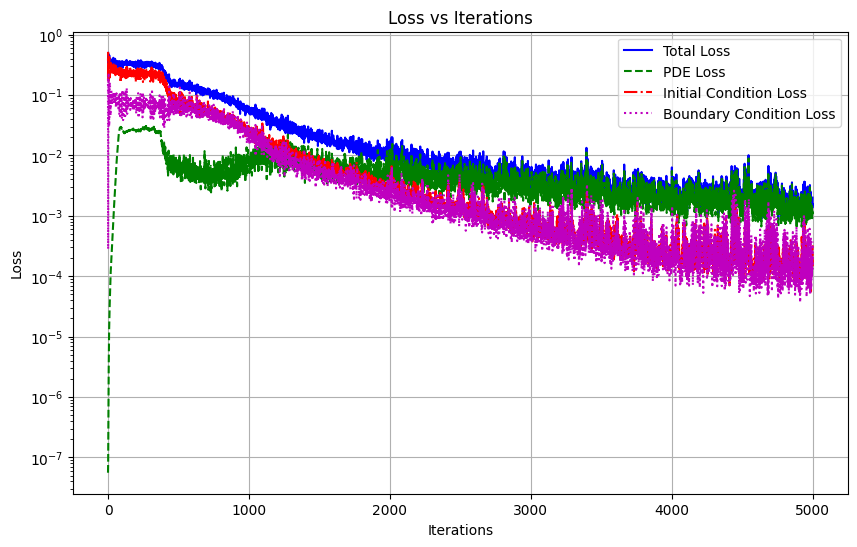

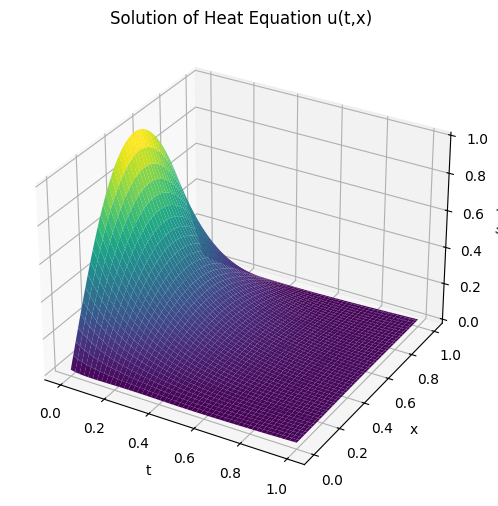

In [12]:
# Set hyperparameters
hidden_size = 200
num_epochs = 5000
batch_size = 100
learning_rate = 1e-3
eval_every = 100

# Train the model
model, total_losses, pde_losses, ic_losses, bc_losses = train_dgm(
    hidden_size, num_epochs, batch_size, learning_rate, sigma, L, T, eval_every)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses)

# Plot the solution
plot_solution(model, L, T)

## Different initial distribution and longer time horizon

Try with a different initial distribution (e.g., a Gaussian) and with a longer time horizon.

Epoch 1000, Total: 4.11e-03, PDE: 2.62e-03, IC: 1.34e-04, BC: 1.46e-04
Epoch 2000, Total: 1.33e-03, PDE: 1.24e-03, IC: 7.30e-06, BC: 1.53e-05
Epoch 3000, Total: 5.61e-04, PDE: 2.39e-04, IC: 2.23e-05, BC: 9.93e-05
Epoch 4000, Total: 5.57e-04, PDE: 3.08e-04, IC: 1.94e-05, BC: 5.50e-05
Epoch 5000, Total: 3.39e-04, PDE: 2.87e-04, IC: 4.44e-06, BC: 7.68e-06
Epoch 6000, Total: 2.09e-04, PDE: 1.86e-04, IC: 1.90e-06, BC: 3.85e-06
Epoch 7000, Total: 2.25e-04, PDE: 1.73e-04, IC: 4.16e-06, BC: 1.08e-05
Epoch 8000, Total: 1.37e-04, PDE: 1.12e-04, IC: 2.41e-06, BC: 8.08e-07


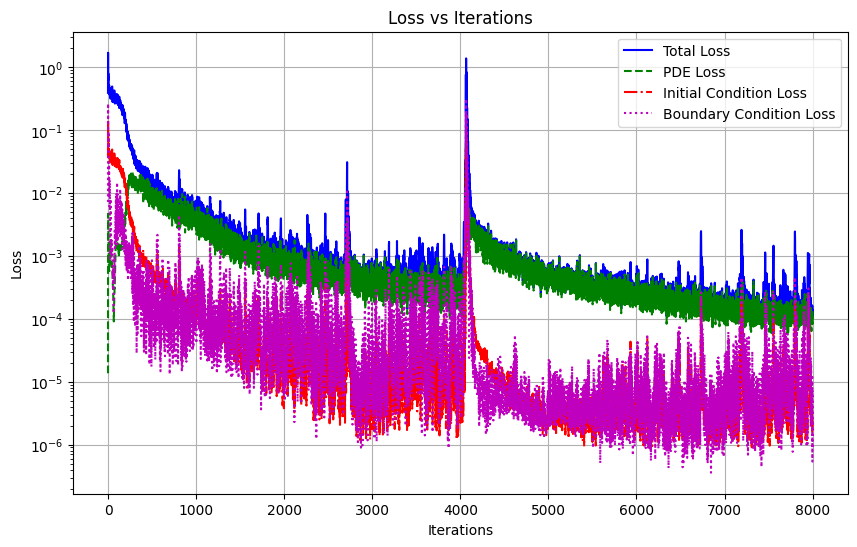

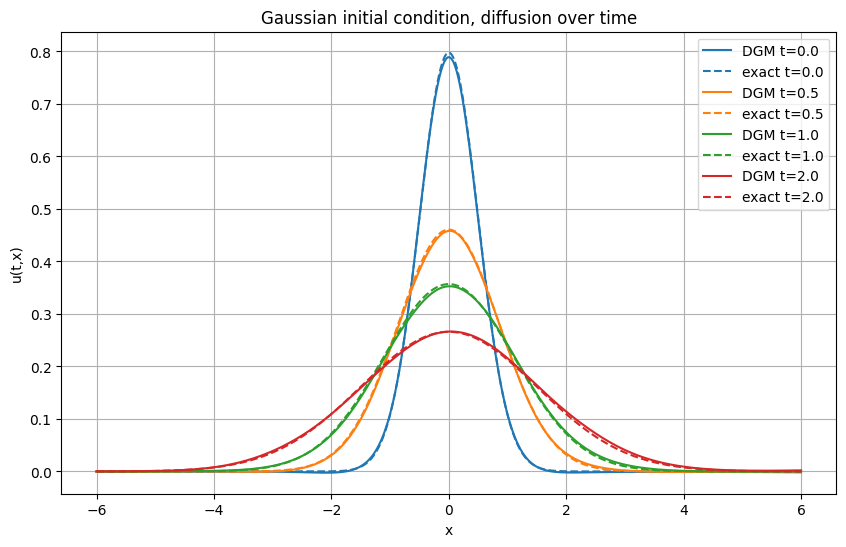

In [13]:
import math

# Gaussian IC on a symmetric domain, longer horizon
X  = 6.0    # x in [-X, X] for it to be centered
T2 = 2.0    # was T = 1.0
s0 = 0.5    # initial std of the Gaussian

class DGMNet2(nn.Module):
    def __init__(self, hidden_size, X, T):
        super().__init__()
        self.X, self.T = X, T
        self.fc1 = nn.Linear(2, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.fc4 = nn.Linear(hidden_size, 1)
        self.activation = nn.Tanh()

    def forward(self, tx):
        out = torch.cat([tx[:, 0:1] / self.T, tx[:, 1:2] / self.X], dim=1)
        out = self.activation(self.fc1(out))
        out = self.activation(self.fc2(out))
        out = self.activation(self.fc3(out))
        return self.fc4(out)

def gaussian_ic_loss(model, x, s0):
    t = torch.zeros_like(x)
    u_pred = model(torch.cat([t, x], dim=1))
    u_true = torch.exp(-x**2 / (2 * s0**2)) / math.sqrt(2 * math.pi * s0**2)
    return torch.mean((u_pred - u_true)**2)

def gaussian_bc_loss(model, t, X):
    xm = -X * torch.ones_like(t)
    xp =  X * torch.ones_like(t)
    return torch.mean(model(torch.cat([t, xm], 1))**2 + model(torch.cat([t, xp], 1))**2)

def exact_gaussian(t, x, sigma, s0):
    var = s0**2 + sigma**2 * t
    return torch.exp(-x**2 / (2 * var)) / torch.sqrt(2 * math.pi * var)

def train_gauss(hidden_size, num_epochs, batch_size, lr, sigma, s0, X, T, eval_every=500):
    model = DGMNet2(hidden_size, X, T)
    opt = optim.Adam(model.parameters(), lr=lr)
    total, pde_l, ic_l, bc_l = [], [], [], []
    for epoch in range(1, num_epochs + 1):
        x_b  = 2 * X * torch.rand(batch_size, 1) - X
        t_b  = T * torch.rand(batch_size, 1)
        x_ic = 2 * X * torch.rand(batch_size, 1) - X

        loss_pde = (pde_residual(model, t_b, x_b, sigma)**2).mean()
        loss_ic  = gaussian_ic_loss(model, x_ic, s0)
        loss_bc  = gaussian_bc_loss(model, t_b, X)
        loss = loss_pde + 10.0 * loss_ic + loss_bc

        opt.zero_grad()
        loss.backward()
        opt.step()

        total.append(loss.item()); pde_l.append(loss_pde.item())
        ic_l.append(loss_ic.item()); bc_l.append(loss_bc.item())
        if epoch % eval_every == 0:
            print(f"Epoch {epoch}, Total: {loss.item():.2e}, PDE: {loss_pde.item():.2e}, "
                  f"IC: {loss_ic.item():.2e}, BC: {loss_bc.item():.2e}")
    return model, total, pde_l, ic_l, bc_l

def plot_gauss_slices(model, sigma, s0, X, T, times=(0.0, 0.5, 1.0, 2.0)):
    x = torch.linspace(-X, X, 400).unsqueeze(1)
    plt.figure(figsize=(10, 6))
    for i, tv in enumerate(times):
        t = tv * torch.ones_like(x)
        with torch.no_grad():
            u = model(torch.cat([t, x], dim=1))
        c = f"C{i}"
        plt.plot(x.squeeze(), u.squeeze(), color=c, label=f"DGM t={tv}")
        plt.plot(x.squeeze(), exact_gaussian(t, x, sigma, s0).squeeze(),
                 color=c, linestyle="--", label=f"exact t={tv}")
    plt.xlabel("x"); plt.ylabel("u(t,x)"); plt.legend(); plt.grid(True)
    plt.title("Gaussian initial condition, diffusion over time")
    plt.show()

model_g, tot, pde_l, ic_l, bc_l = train_gauss(
    hidden_size=200, num_epochs=8000, batch_size=512,
    lr=1e-3, sigma=sigma, s0=s0, X=X, T=T2, eval_every=1000
)
plot_losses(tot, pde_l, ic_l, bc_l)
plot_gauss_slices(model_g, sigma, s0, X, T2)

# DGM for 2D Advection-Diffusion Equation

## First version

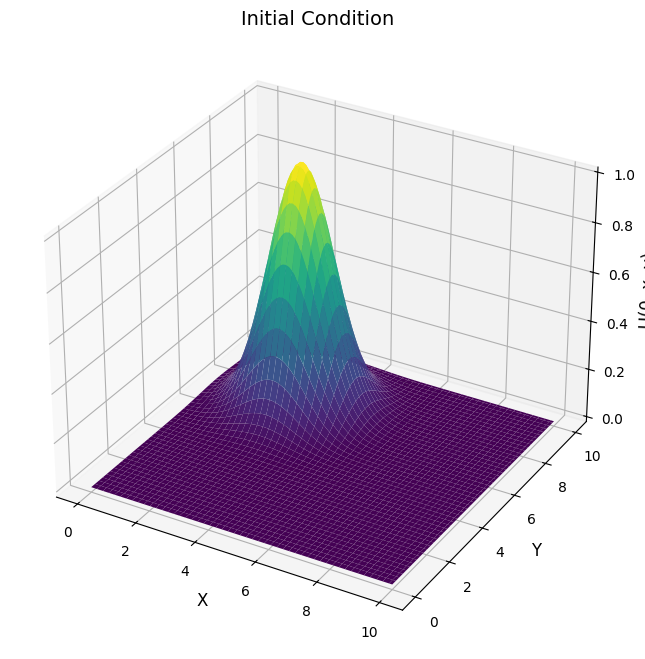

Iteration 0, Total Loss: 9.98e-02, PDE Loss: 7.09e-09, IC Loss: 4.58e-02, BC Loss: 5.40e-02
Iteration 100, Total Loss: 3.21e-02, PDE Loss: 9.63e-06, IC Loss: 2.99e-02, BC Loss: 2.24e-03
Iteration 200, Total Loss: 2.77e-02, PDE Loss: 3.60e-05, IC Loss: 2.58e-02, BC Loss: 1.89e-03
Iteration 300, Total Loss: 2.78e-02, PDE Loss: 3.22e-04, IC Loss: 2.35e-02, BC Loss: 4.01e-03
Iteration 400, Total Loss: 3.12e-02, PDE Loss: 2.94e-04, IC Loss: 2.82e-02, BC Loss: 2.72e-03
Iteration 500, Total Loss: 1.78e-02, PDE Loss: 5.51e-04, IC Loss: 1.50e-02, BC Loss: 2.24e-03
Iteration 600, Total Loss: 1.77e-02, PDE Loss: 6.37e-04, IC Loss: 1.43e-02, BC Loss: 2.81e-03
Iteration 700, Total Loss: 1.68e-02, PDE Loss: 8.37e-04, IC Loss: 1.41e-02, BC Loss: 1.84e-03
Iteration 800, Total Loss: 2.16e-02, PDE Loss: 7.85e-04, IC Loss: 1.72e-02, BC Loss: 3.61e-03
Iteration 900, Total Loss: 2.30e-02, PDE Loss: 7.40e-04, IC Loss: 1.75e-02, BC Loss: 4.79e-03
Iteration 1000, Total Loss: 8.79e-03, PDE Loss: 7.62e-04, IC L

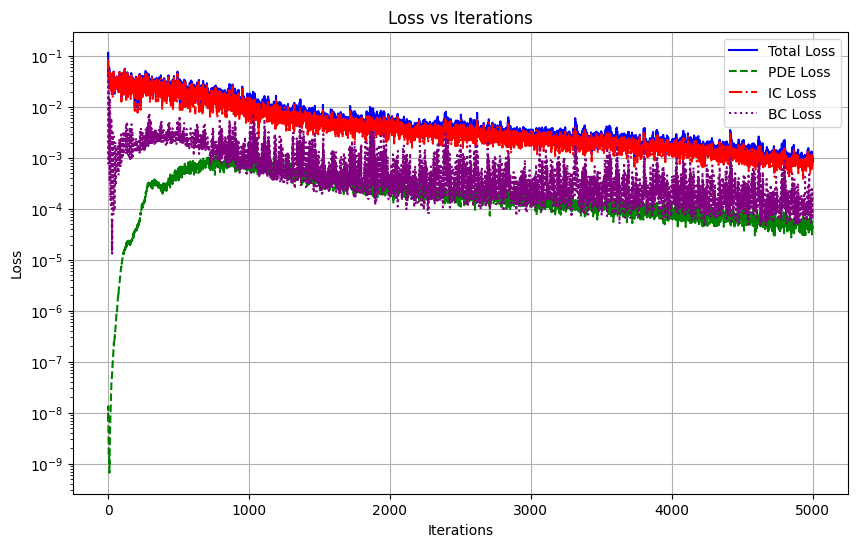

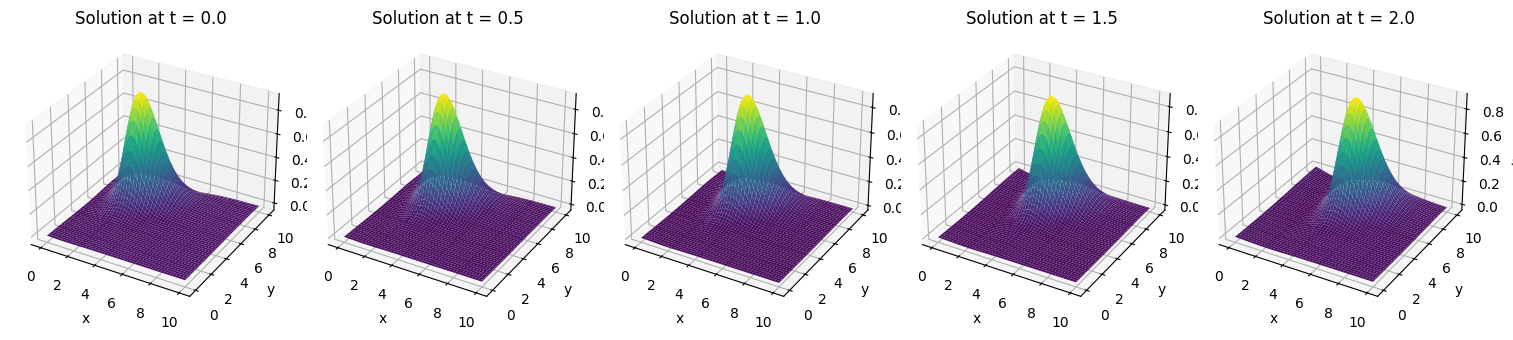

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Neural Network model for DGM
class DGMNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(DGMNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.fc4 = nn.Linear(hidden_size, hidden_size)
        self.fc5 = nn.Linear(hidden_size, output_size)
        self.activation = nn.Sigmoid()

    def forward(self, t, x, y):
        inputs = torch.cat([t, x, y], dim=1)
        h = self.activation(self.fc1(inputs))
        h = self.activation(self.fc2(h))
        h = self.activation(self.fc3(h))
        h = self.activation(self.fc4(h))
        return self.fc5(h)

# Bell-shaped initial condition (Gaussian)
def initial_condition(x, y):
    return torch.exp(-0.5 * ((x - 3.0)**2 + (y - 7.0)**2))

# TODO: Modify the code so that there is a unique IC function
def initial_condition_np(x, y):
    return np.exp(-0.5 * ((x - 3.0)**2 + (y - 7.0)**2))

# Initial condition loss
def initial_condition_loss(model, t0, x, y):
    u_pred_initial = model(t0, x, y)
    u_initial = initial_condition(x, y)
    return torch.mean((u_pred_initial - u_initial)**2)

# Boundary condition loss
def boundary_condition_loss(model, t, x_bound, y_bound):
    u_x_bound = model(t, x_bound, y_bound)
    return torch.mean(u_x_bound**2)

# PDE residual
def pde_residual(model, t, x, y, vx, vy, D):
    # Ensure that t and x require gradients
    t.requires_grad_()
    x.requires_grad_()
    y.requires_grad_()

    u = model(t, x, y)

    u_t = torch.autograd.grad(u,t,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = torch.autograd.grad(u,x,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_y = torch.autograd.grad(u,y,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x,x,grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y,y,grad_outputs=torch.ones_like(u), create_graph=True)[0]

    # Advection-diffusion equation
    residual = u_t + vx * u_x + vy * u_y - D * (u_xx + u_yy)
    return residual

# Training loop
def train_dgm(model, optimizer, num_iterations, batch_size, t_range, x_range, y_range, D, vx, vy, eval_every=100):
    total_losses = []
    pde_losses = []
    ic_losses = []
    bc_losses = []

    for iteration in range(num_iterations):
        # Sample random points in the interior for the PDE residual
        t = torch.rand(batch_size, 1) * t_range
        x = torch.rand(batch_size, 1) * x_range
        y = torch.rand(batch_size, 1) * y_range

        # Concatenate inputs for the PDE
        inputs = torch.cat([t, x, y], dim=1)  # All tensors should be (100, 1) size

        # Compute PDE residual
        residual = pde_residual(model, t, x, y, vx, vy, D)

        # Compute loss components
        pde_loss = torch.mean(residual**2)

        # Compute initial condition loss
        t0 = torch.zeros(batch_size, 1)
        ic_loss = initial_condition_loss(model, t0, x, y)

        # Compute boundary condition loss (at x=0, x=1, y=0, y=1)
        t_bc = torch.rand(200, 1) * t_range
        x_bound = torch.cat([torch.zeros(100, 1), x_range*torch.ones(100, 1)], dim=0)  # x=0 and x=x_range
        y_bound = torch.rand(200, 1) * y_range  # Any y within the domain
        bc_loss_x = boundary_condition_loss(model, t_bc, x_bound, y_bound)

        x_bound = torch.rand(200, 1) * x_range  # Any x within the domain

        y_bound = torch.cat([torch.zeros(100, 1), y_range*torch.ones(100, 1)], dim=0)  # y=0 and y=y_range
        x_bound = torch.rand(200, 1) * x_range  # Any x within the domain
        bc_loss_y = boundary_condition_loss(model, t_bc, x_bound, y_bound)

        # Total boundary condition loss
        bc_loss = bc_loss_x + bc_loss_y

        # Total loss
        total_loss = pde_loss + ic_loss + bc_loss

        # Backpropagation and optimization
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        # Store losses
        total_losses.append(total_loss.item())
        pde_losses.append(pde_loss.item())
        ic_losses.append(ic_loss.item())
        bc_losses.append(bc_loss.item())

        # Print the losses every eval_every iterations
        if iteration % eval_every == 0:
            print(f"Iteration {iteration}, Total Loss: {total_loss.item():.2e}, PDE Loss: {pde_loss.item():.2e}, IC Loss: {ic_loss.item():.2e}, BC Loss: {bc_loss.item():.2e}")

    return total_losses, pde_losses, ic_losses, bc_losses

# Plot the initial condition
def plot_initial_condition(x_range, y_range):
    # Define the spatial domain
    x = np.linspace(0, x_range, 100)
    y = np.linspace(0, y_range, 100)

    # Create a meshgrid for 3D plotting
    X, Y = np.meshgrid(x, y)

    Z = initial_condition_np(X, Y)

    # Plot the 3D surface
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none')

    # Customize the plot
    ax.set_title('Initial Condition', fontsize=14)
    ax.set_xlabel('X', fontsize=12)
    ax.set_ylabel('Y', fontsize=12)
    ax.set_zlabel('U(0, x, y)', fontsize=12)

    # Show the plot
    plt.show()

# Plot the learned solution
def plot_solution(model, t_values, x_range, y_range):
    # Create grid for x and y in the specified ranges
    x_test = torch.linspace(0, x_range, 100).unsqueeze(1)
    y_test = torch.linspace(0, y_range, 100).unsqueeze(1)

    # Evaluate the solution for each time in t_values
    fig = plt.figure(figsize=(15, 12))

    for i, t in enumerate(t_values):
        # Create meshgrid for x and y
        x_grid, y_grid = torch.meshgrid(x_test.squeeze(), y_test.squeeze())
        t_grid = t * torch.ones_like(x_grid)

        # Get the model's prediction
        u_pred = model(t_grid.reshape(-1, 1), x_grid.reshape(-1, 1), y_grid.reshape(-1, 1)).detach().cpu().numpy()
        u_pred = u_pred.reshape(100, 100)  # Reshape back to grid

        # Plot the solution at the current time point
        ax = fig.add_subplot(2, len(t_values), i + 1, projection='3d')
        ax.plot_surface(x_grid.cpu().numpy(), y_grid.cpu().numpy(), u_pred, cmap='viridis')
        ax.set_title(f"Solution at t = {t:.1f}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_zlabel("u(t, x, y)")

    plt.tight_layout()
    plt.show()

# Plot the loss vs iterations
def plot_losses(total_losses, pde_losses, ic_losses, bc_losses):
    iterations = np.arange(len(total_losses))
    plt.figure(figsize=(10, 6))
    plt.semilogy(iterations, total_losses, label='Total Loss', color='blue', linestyle='-')
    plt.semilogy(iterations, pde_losses, label='PDE Loss', color='green', linestyle='--')
    plt.semilogy(iterations, ic_losses, label='IC Loss', color='red', linestyle='-.')
    plt.semilogy(iterations, bc_losses, label='BC Loss', color='purple', linestyle=':')
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.title('Loss vs Iterations')
    plt.legend()
    plt.grid(True)
    plt.show()

# Parameters
T = 1.0  # Final time
L = 10.0  # Domain size
D = 0.01  # Diffusion coefficient
vx, vy = 5.0, -5.0  # Velocity components
# Hyperparameters
hidden_size = 200
batch_size = 200
num_iterations = 5000
learning_rate = 1e-3

# Call the function to plot the initial condition
plot_initial_condition(L, L)

# Model and optimizer
model = DGMNet(input_size=3, hidden_size=hidden_size, output_size=1)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
total_losses, pde_losses, ic_losses, bc_losses = train_dgm(
    model, optimizer, num_iterations=num_iterations, batch_size=batch_size,
    t_range=T, x_range=L, y_range=L, D=0.01, vx=0.9, vy=0.1, eval_every=100)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses)

# Plot the final solution
t_values = [0.0, 0.5, 1.0, 1.5, 2.0]
plot_solution(model, t_values, x_range=L, y_range=L)

## Different initial condition

Try with:
$$
  \exp(-10((x - 3.0)^2 + (y - 7.0)^2))
$$
This initial distribution is more "peaky" so it is harder to catch for the NN.

In [ ]:
# TODO

# DGM Original Architecture

Recall that the architecture proposed in the DGM paper for time-dependent PDEs is:
\begin{align*}
S^1 &= \sigma(W^{1} \vec{x} + b^1), \\
Z^{\ell} &= \sigma(U^{z, \ell} \vec{x} + W^{z, \ell} S^{\ell} + b^{z, \ell}), \quad \ell = 1, \dots, L, \\
G^{\ell} &= \sigma(U^{g, \ell} \vec{x} + W^{g, \ell} S^1 + b^{g, \ell}), \quad \ell = 1, \dots, L, \\
R^{\ell} &= \sigma(U^{r, \ell} \vec{x} + W^{r, \ell} S^{\ell} + b^{r, \ell}), \quad \ell = 1, \dots, L, \\
H^{\ell} &= \sigma(U^{h, \ell} \vec{x} + W^{h, \ell} (S^{\ell} \odot R^{\ell}) + b^{h, \ell}), \quad \ell = 1, \dots, L, \\
S^{\ell+1} &= (1 - G^{\ell}) \odot H^{\ell} + Z^{\ell} \odot S^{\ell}, \quad \ell = 1, \dots, L, \\
f(t, x; \theta) &= W S^{L+1} + b,
\end{align*}
where the input is $\vec{x} = (t,x)$ and $f(t, x; \theta)$ denotes the final output.

We revisit the first example (1D heat equation) with this architecture.

In [ ]:
class DGMNetArchi(nn.Module):
    def __init__(self, layer_dims, activation):
        """
        Args:
            layer_dims (list of int): The number of neurons in each layer (including recurrent layers).
            activation (nn.Module): Activation function to use (e.g., nn.Sigmoid(), nn.Tanh(), etc.).
        """
        super(DGMNetArchi, self).__init__()
        input_dim = 2  # t and x are the input
        self.L = len(layer_dims)  # Number of layers
        self.activation = activation

        # Define the weights and biases for the input-to-hidden connection in the first layer
        self.W1 = nn.Linear(input_dim, layer_dims[0])
        self.b1 = nn.Parameter(torch.zeros(layer_dims[0]))

        # Define the weights and biases for each recurrent layer
        # Use the syntax: [f(x) for x in my_list]
        self.Uz = nn.ModuleList([nn.Linear(input_dim, layer_dims[l]) for l in range(self.L)])
        self.Wz = nn.ModuleList([nn.Linear(layer_dims[l], layer_dims[l]) for l in range(self.L)])
        self.bz = nn.ParameterList([nn.Parameter(torch.zeros(layer_dims[l])) for l in range(self.L)])

        self.Ug = nn.ModuleList([nn.Linear(input_dim, layer_dims[l]) for l in range(self.L)])
        self.Wg = nn.ModuleList([nn.Linear(layer_dims[0], layer_dims[l]) for l in range(self.L)])  # Connects to S^1
        self.bg = nn.ParameterList([nn.Parameter(torch.zeros(layer_dims[l])) for l in range(self.L)])

        self.Ur = nn.ModuleList([nn.Linear(input_dim, layer_dims[l]) for l in range(self.L)])
        self.Wr = nn.ModuleList([nn.Linear(layer_dims[l], layer_dims[l]) for l in range(self.L)])
        self.br = nn.ParameterList([nn.Parameter(torch.zeros(layer_dims[l])) for l in range(self.L)])

        self.Uh = nn.ModuleList([nn.Linear(input_dim, layer_dims[l]) for l in range(self.L)])
        self.Wh = nn.ModuleList([nn.Linear(layer_dims[l], layer_dims[l]) for l in range(self.L)])
        self.bh = nn.ParameterList([nn.Parameter(torch.zeros(layer_dims[l])) for l in range(self.L)])

        # Output layer
        self.W_out = nn.Linear(layer_dims[-1], 1)
        self.b_out = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        # First layer: S^1 = sigma(W^1 x + b^1)
        S1 = # TODO

        # Initialize S^ell = S^1 for the recurrence
        S = S1

        # Recurrent structure
        for l in range(self.L):
            # Compute Z^ell
            Z = # TODO

            # Compute G^ell
            G = # TODO

            # Compute R^ell
            R = # TODO

            # Compute H^ell
            H = # TODO

            # Update S^{ell+1} = (1 - G^ell) * H^ell + Z^ell * S^ell
            S = # TODO

        # Output layer: f(t, x; θ) = W S^{L+1} + b
        output = # TODO
        return output

In [ ]:
# Define the PDE residual
def pde_residual(model, t, x, sigma):
    # Ensure that t and x require gradients
    t.requires_grad_()
    x.requires_grad_()

    # Pass input through the model to get u(t, x)
    tx = torch.cat([t, x], dim=1)
    u = model(tx)  # u(t, x)

    # Compute gradients with autograd
    u_t = # TODO
    u_x = # TODO
    u_xx = # TODO

    # PDE residual: u_t - 0.5 * sigma^2 * u_xx = 0
    residual = # TODO
    return residual

# Initial condition: u(0, x) = sin(pi * x / L)
def initial_condition_loss(model, x, L):
    t = torch.zeros_like(x)  # t=0
    u_pred = model(torch.cat([t, x], dim=1))
    u_true = torch.sin(np.pi * x / L)
    return torch.mean((u_pred - u_true) ** 2)

# Boundary conditions: u(t, 0) = u(t, L) = 0
def boundary_condition_loss(model, t, L):
    x0 = torch.zeros_like(t)  # x=0
    xL = L * torch.ones_like(t)  # x=L
    u0_pred = model(torch.cat([t, x0], dim=1))
    uL_pred = model(torch.cat([t, xL], dim=1))
    return torch.mean((u0_pred - 0) ** 2) + torch.mean((uL_pred - 0) ** 2)

# Training function
def train_dgm_archi(layer_dims, activation, num_epochs, batch_size, learning_rate, sigma, L, T, eval_every=100):
    model = DGMNetArchi(layer_dims, activation)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    total_losses = []
    pde_losses = []
    ic_losses = []
    bc_losses = []

    for epoch in range(0,num_epochs+1):
        # Sample random points in the domain
        x_batch = L * torch.rand(batch_size, 1)  # x in [0, L]
        t_batch = T * torch.rand(batch_size, 1)  # t in [0, T]

        # Compute losses
        loss_pde = torch.mean(pde_residual(model, t_batch, x_batch, sigma) ** 2)
        loss_ic = initial_condition_loss(model, x_batch, L)
        loss_bc = boundary_condition_loss(model, t_batch, L)
        loss = loss_pde + loss_ic + loss_bc

        # Backpropagation and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Record losses
        total_losses.append(loss.item())
        pde_losses.append(loss_pde.item())
        ic_losses.append(loss_ic.item())
        bc_losses.append(loss_bc.item())

        # Print progress with each loss component
        if epoch % eval_every == 0:
            print(f"Epoch {epoch}, Total Loss: {loss.item():.2e}, PDE Loss: {loss_pde.item():.2e}, IC Loss: {loss_ic.item():.2e}, BC Loss: {loss_bc.item():.2e}")

    return model, total_losses, pde_losses, ic_losses, bc_losses

# Plot the losses
def plot_losses(total_losses, pde_losses, ic_losses, bc_losses):
    iterations = range(len(total_losses))

    plt.figure(figsize=(10, 6))

    # Plot the total loss and each component
    plt.semilogy(iterations, total_losses, label="Total Loss", linestyle='-', color='b')
    plt.semilogy(iterations, pde_losses, label="PDE Loss", linestyle='--', color='g')
    plt.semilogy(iterations, ic_losses, label="Initial Condition Loss", linestyle='-.', color='r')
    plt.semilogy(iterations, bc_losses, label="Boundary Condition Loss", linestyle=':', color='m')

    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.title("Loss vs Iterations")
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot the solution u(t,x)
def plot_solution(model, L, T):
    t_vals = torch.linspace(0, T, 100)
    x_vals = torch.linspace(0, L, 100)
    t_grid, x_grid = torch.meshgrid(t_vals, x_vals)
    t_flat = t_grid.flatten().unsqueeze(1)
    x_flat = x_grid.flatten().unsqueeze(1)

    u_pred = model(torch.cat([t_flat, x_flat], dim=1))
    u_pred = u_pred.reshape(t_grid.shape).detach().numpy()

    # Plot 3D surface of the solution
    fig = plt.figure(figsize=(10, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(t_grid.numpy(), x_grid.numpy(), u_pred, cmap='viridis')
    ax.set_xlabel('t')
    ax.set_ylabel('x')
    ax.set_zlabel('u(t,x)')
    plt.title('Solution of Heat Equation u(t,x)')
    ax.set_box_aspect(None, zoom=0.85)
    plt.show()

# Set parameters
sigma = 0.2  # Diffusion coefficient
L = 1.0  # Spatial domain length
T = 2.0  # Temporal domain length

In [ ]:
# Set hyperparameters
layer_dims = [50, 50, 50]  # 3 recurrent layers with 50 neurons each
activation = nn.Tanh()
num_epochs = 500
batch_size = 100
learning_rate = 1e-3
eval_every = 10

# Train the model
model, total_losses, pde_losses, ic_losses, bc_losses = train_dgm_archi(
    layer_dims, activation, num_epochs, batch_size, learning_rate, sigma, L, T, eval_every)

# Plot the losses
plot_losses(total_losses, pde_losses, ic_losses, bc_losses)

# Plot the solution
plot_solution(model, L, T)

We obtain better results than with feedforward fully connected NN, even with fewer training steps.

# Exercises

TODOs:
- make the minibatch size a hyperparameter
- add coefficients to weigh the importance of each term in the total loss (residual, IC and BC)
- use a testing set
- repeat the experiments several times and repor the average losses +/- stddev
- try the DGM architecture in dim 2, or higher dim.